# Planificación Automática para la Gestión Inteligente de un Almacén Autónomo

---

## 1. Contexto y Objetivos

Una empresa de logística busca transformar su centro de distribución mediante la transición de una operativa reactiva a un sistema de planificación deliberativo. El escenario de trabajo consiste en un almacén automatizado compuesto por cuatro zonas críticas (**A, B, C y D**), cada una con roles específicos en la cadena de suministro.

### 1.1. Contexto de Almacén
El almacén presenta una configuración compleja que impone retos estratégicos al robot:

- **Caminos no Dirigidos:** A diferencia de un entorno abierto, los caminos entre zonas son de sentido único en varios tramos (representados mediante un grafo dirigido). Por ejemplo, el robot puede ir de D a A, pero no puede retornar directamente sin pasar por otras zonas intermedias.

- **Seguridad de Zonas:** Las zonas cuentan con cerramientos inteligentes. Una zona puede estar `cerrada`, impidiendo el paso o la manipulación de objetos en su interior. El robot debe estar físicamente en la zona para ejecutar la acción de `abrir_zona` (simulando la activación de un panel de control local).

- **Gestión de Carga por Peso:** El almacén maneja dos tipos de cajas con propiedades distintas: `ligeras` y `pesadas`. Mientras que las cajas ligeras pueden moverse manualmente, las cajas pesadas requieren obligatoriamente el uso de una carretilla elevadora.

- **Caminos Obstruidos:** La eficiencia del transporte se ve amenazada por obstáculos dinámicos en las rutas adyacentes. El robot debe identificar si un camino tiene un `obstaculo` y ejecutar la acción `apartar_obstaculo` para que el camino pase a estado `libre` antes de cualquier transporte.

### 1.2. Limitaciones del Contexto

1. **Incompatibilidad de Herramientas:** El robot no puede transportar cajas ligeras si lleva la carretilla acoplada, lo que le obliga a planificar turnos de 'recogida' y 'suelta' de la herramienta dependiendo de la prioridad de la carga.

2. **Dependencia de Infraestructura:** El robot no puede atravesar o mover cajas hacia zonas que no hayan sido previamente abiertas o caminos que no hayan sido despejados.

**Objetivo Final:** Generar una secuencia óptima de acciones para que las tres cajas alcancen sus destinos de expedición específicos partiendo de un estado inicial donde el robot está desubicado, las puertas bloqueadas y los caminos obstruidos.

## 2. Formalización del Dominio y Problema (PDDL)

Para que un sistema de planificación clásica (STRIPS) resuelva el problema, se debe formalizar los componentes del almacén mediante predicados (estados) y acciones (operadores).

### 2.1. Definición de Predicados

Los predicados definen las propiedades de los objetos y sus relaciones en un momento dado:

- `(robot_en ?z)`: Indica la ubicación actual del robot en la zona `?z`.

- `(caja_en ?c ?z)`: Asocia una caja `?c` con una zona `?z`.

- `(pesada ?c)` / `(ligera ?c)`: Predicados estáticos que definen el peso de la mercancía.

- `(abierta ?z)` / `(cerrada ?z)`: Estado de los sistemas de seguridad de la zona `?z`. Un robot solo puede entrar o mover objetos en zonas `abierta`.

- `(obstaculo ?f ?to)` / `(libre ?f ?to)`: Define si el trayecto entre dos zonas adyacentes está bloqueado por obstáculos o despejado para el tránsito.

- `(con_carretilla)` / `(sin_carretilla)`: Estado de inventario del robot. Determina su capacidad para mover cargas pesadas.

- `(adyacente ?z1 ?z2)`: Conectividad física (dirigida) entre zonas.

### 2.2. Definición de Acciones

Cada acción requiere **precondiciones** para ejecutarse y produce **efectos** (ADD/DEL) en el estado:

1. **`moverse(?from, ?to)`**: 
   - *Precondición*: El robot está en `?from`, hay adyacencia a `?to`, la zona de destino está `abierta` y el camino está `libre`.
   - *Efecto*: El robot deja de estar en `?from` y pasa a estar en `?to`.

2. **`abrir_zona(?z)`**:
   - *Precondición*: El robot está físicamente en `?z` y la zona está `cerrada`.
   - *Efecto*: La zona pasa a estar `abierta` y deja de estar `cerrada`.

3. **`apartar_obstaculo(?from, ?to)`**:
   - *Precondición*: El robot está en `?from` y hay un `obstaculo` detectado hacia `?to`.
   - *Efecto*: El camino pasa a estar `libre` y se elimina el hecho `obstaculo`.

4. **`coger_carretilla(?z)`** / **`soltar_carretilla(?z)`**:
   - Permite al robot cambiar su estado de carga. Recogerla requiere que la carretilla esté en la zona del robot y que este tenga las manos libres (`sin_carretilla`).

5. **`transportar_caja_ligera(?from, ?to, ?c)`**:
   - Requiere que el robot esté `sin_carretilla`. Ambas zonas (`from` y `to`) deben estar `abierta`.

6. **`transportar_caja_pesada(?from, ?to, ?c)`**:
   - Requiere obligatoriamente que el robot esté `con_carretilla`.

### 2.2. Implementación del Dominio

In [ ]:
domain_pddl = """
(define (domain almacen_logistico)
  (:requirements :strips :typing)
  (:types zona caja)
  
  (:predicates
    (robot_en ?z - zona)
    (caja_en ?c - caja ?z - zona)
    (carretilla_en ?z - zona)
    
    (abierta ?z - zona)
    (cerrada ?z - zona)
    
    (pesada ?c - caja)
    (ligera ?c - caja)
    
    (obstaculo ?from - zona ?to - zona)
    (libre ?from - zona ?to - zona)
    
    (con_carretilla)
    (sin_carretilla)
    
    (adyacente ?z1 ?z2 - zona)
  )

  ;; Acción para mover el robot
  (:action moverse
    :parameters (?from - zona ?to - zona)
    :precondition (and (robot_en ?from) (adyacente ?from ?to) (libre ?from ?to))
    :effect (and (robot_en ?to) (not (robot_en ?from)))
  )

  ;; Acción para recoger la carretilla
  (:action coger_carretilla
    :parameters (?z - zona)
    :precondition (and (robot_en ?z) (carretilla_en ?z) (sin_carretilla) (abierta ?z))
    :effect (and (con_carretilla) (not (sin_carretilla)) (not (carretilla_en ?z)))
  )
  
  ;; Acción para soltar la carretilla
  (:action soltar_carretilla
    :parameters (?z - zona)
    :precondition (and (robot_en ?z) (con_carretilla) (abierta ?z))
    :effect (and (sin_carretilla) (not (con_carretilla)) (carretilla_en ?z))
  )

  ;; Acción para abrir una zona adyacente que está cerrada
  (:action abrir_zona
    :parameters (?z - zona)
    :precondition (and (robot_en ?z) (cerrada ?z))
    :effect (and (abierta ?z) (not (cerrada ?z)))
  )
  
  ;; Acción para apartar un obstáculo de un camino entre dos zonas
  (:action apartar_obstaculo
    :parameters (?from - zona ?to - zona)
    :precondition (and (robot_en ?from) (obstaculo ?from ?to) (adyacente ?from ?to))
    :effect (and (libre ?from ?to) (not (obstaculo ?from ?to)))
  )

  ;; Acción para transportar una caja ligera
  (:action transportar_caja_ligera
    :parameters (?from - zona ?to - zona ?c - caja)
    :precondition (and (robot_en ?from) (caja_en ?c ?from) (ligera ?c) (sin_carretilla) (adyacente ?from ?to) (abierta ?from) (abierta ?to) (libre ?from ?to))
    :effect (and (robot_en ?to) (caja_en ?c ?to) (not (robot_en ?from)) (not (caja_en ?c ?from)))
  )
  
  ;; Acción para transportar una caja pesada (requiere carretilla)
  (:action transportar_caja_pesada
    :parameters (?from - zona ?to - zona ?c - caja)
    :precondition (and (robot_en ?from) (caja_en ?c ?from) (pesada ?c) (con_carretilla) (adyacente ?from ?to) (abierta ?from) (abierta ?to) (libre ?from ?to))
    :effect (and (robot_en ?to) (caja_en ?c ?to) (not (robot_en ?from)) (not (caja_en ?c ?from)))
  )
)
"""

### 2.3. Implementación del Problema

In [ ]:
problem_pddl = """
(define (problem gestion_almacen)
  (:domain almacen_logistico)
  (:objects
    A B C D - zona
    caja1 caja2 caja3 - caja
  )
  (:init
    ;; Estado Inicial
    
    ;; Situación del robot, cajas y carretilla
    (robot_en B)
    (caja_en caja1 D)
    (caja_en caja3 A)
    (caja_en caja2 C)
    (carretilla_en C)
    
    ;; Características del robot
    (sin_carretilla)
    
    ;; Características de las cajas
    (ligera caja1)
    (ligera caja2)
    (pesada caja3)
    
    ;; Características de las zonas
    (cerrada A)
    (abierta B)
    (cerrada C)
    (abierta D)
    
    ;; Definición de adyacencias
    (adyacente A B)
    (adyacente A D)
    
    (adyacente B A)
    (adyacente B C)
    (adyacente B D)
    
    (adyacente C A)
    (adyacente C B)
    (adyacente C D)
    
    (adyacente D A)
    
    ;; Características de adyacencias
    (obstaculo A B) 
    (obstaculo A D)
    (obstaculo B D)
    (obstaculo C B)
    (obstaculo C D)
    
    (libre B A)
    (libre B C)
    (libre C A)
    (libre D A)
    
  )
  (:goal (and (caja_en caja1 C) (caja_en caja2 B) (caja_en caja3 C)))
)
"""

### 2.4. Diagrama Visual del Problema

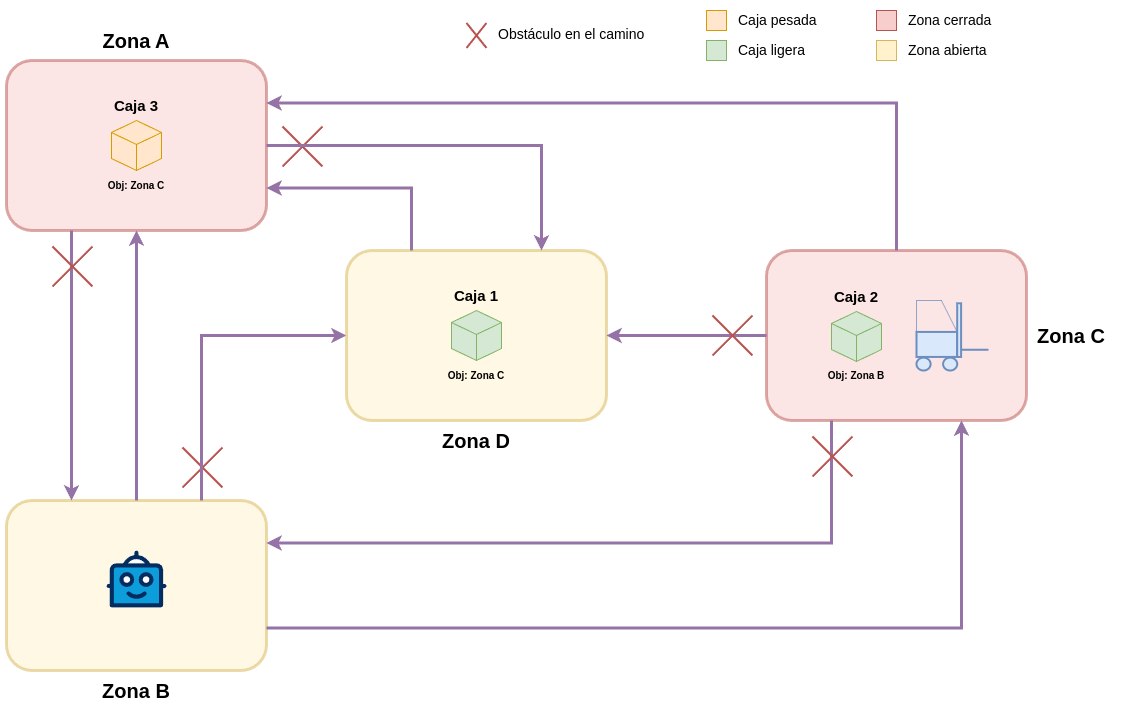

In [ ]:
from pathlib import Path
from IPython.display import Image

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "README.md").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

Image(filename=str(PROJECT_ROOT / "diagrams" / "warehouse_problem.png"))

### 2.5. Generación de Archivos PDDL

In [34]:
PDDL_DIR = PROJECT_ROOT / "pddl"

with open(PDDL_DIR / "domain_raa.pddl", "w", encoding="utf-8") as f:
    f.write(domain_pddl)
with open(PDDL_DIR / "problem_raa.pddl", "w", encoding="utf-8") as f:
    f.write(problem_pddl)
print("PDDL files generated in", PDDL_DIR)

Archivos PDDL generados.


### 2.6. Ejecución con Pyperplan
Se utiliza el buscador `astar` (A*) con la heurística `hadd` para obtener un plan eficiente.

In [37]:
import subprocess

domain_file = PDDL_DIR / "domain_raa.pddl"
problem_file = PDDL_DIR / "problem_raa.pddl"
result = subprocess.run(
    ["python", "-m", "pyperplan", "-s", "astar", "-H", "hadd", str(domain_file), str(problem_file)],
    text=True,
    capture_output=True,
    cwd=PROJECT_ROOT,
)

print(result.stdout)
print(result.stderr)

solution_file = PDDL_DIR / "problem_raa.pddl.soln"
if solution_file.exists():
    print("\n--- Pyperplan A* plan ---")
    print(solution_file.read_text(encoding="utf-8"))

2026-05-16 16:43:38,138 INFO     using search: astar_search
2026-05-16 16:43:38,138 INFO     using heuristic: hAddHeuristic
2026-05-16 16:43:38,138 INFO     Parsing Domain /home/mdiaz/Escritorio/Universidad/Master IA/Q2/Machine Learning II/RAA/domain_raa.pddl
2026-05-16 16:43:38,139 INFO     Parsing Problem /home/mdiaz/Escritorio/Universidad/Master IA/Q2/Machine Learning II/RAA/problem_raa.pddl
2026-05-16 16:43:38,140 INFO     12 Predicates parsed
2026-05-16 16:43:38,140 INFO     7 Actions parsed
2026-05-16 16:43:38,140 INFO     7 Objects parsed
2026-05-16 16:43:38,140 INFO     0 Constants parsed
2026-05-16 16:43:38,140 INFO     Grounding start: gestion_almacen
2026-05-16 16:43:38,141 INFO     Relevance analysis removed 0 facts
2026-05-16 16:43:38,141 INFO     Grounding end: gestion_almacen
2026-05-16 16:43:38,141 INFO     48 Variables created
2026-05-16 16:43:38,141 INFO     57 Operators created
2026-05-16 16:43:38,141 INFO     Search start: gestion_almacen
2026-05-16 16:43:38,141 INF

## 3. Implementación de un Planificador Propio

A continuación, se implementa un planificador basado en el algoritmo **A***. Se representan los estados como `frozenset` de predicados para garantizar inmutabilidad y eficiencia en la búsqueda.

In [36]:
import heapq

class State:
    def __init__(self, predicates, g=0, h=0, parent=None, action=None):
        self.predicates = frozenset(predicates)
        self.g = g
        self.h = h
        self.parent = parent
        self.action = action

    @property
    def f(self):
        return self.g + self.h

    def __lt__(self, other):
        return self.f < other.f

    def __eq__(self, other):
        return self.predicates == other.predicates

    def __hash__(self):
        return hash(self.predicates)

def apply(action_name, args, state_predicates):
    """Función pura que aplica una acción a un estado si se cumplen las precondiciones."""
    new_predicates = set(state_predicates)
    
    # Lógica de las acciones STRIPS
    if action_name == "moverse":
        f, t = args
        if ('robot_en', f) in state_predicates and ('adyacente', f, t) in state_predicates and ('libre', f, t) in state_predicates:
            new_predicates.remove(('robot_en', f))
            new_predicates.add(('robot_en', t))
            return new_predicates
            
    elif action_name == "coger_carretilla":
        z = args[0]
        if ('robot_en', z) in state_predicates and ('carretilla_en', z) in state_predicates and ('sin_carretilla',) in state_predicates and ('abierta', z) in state_predicates:
            new_predicates.remove(('carretilla_en', z))
            new_predicates.remove(('sin_carretilla',))
            new_predicates.add(('con_carretilla',))
            return new_predicates

    elif action_name == "soltar_carretilla":
        z = args[0]
        if ('robot_en', z) in state_predicates and ('con_carretilla',) in state_predicates and ('abierta', z) in state_predicates:
            new_predicates.remove(('con_carretilla',))
            new_predicates.add(('carretilla_en', z))
            new_predicates.add(('sin_carretilla',))
            return new_predicates

    elif action_name == "abrir_zona":
        z = args[0]
        if ('robot_en', z) in state_predicates and ('cerrada', z) in state_predicates:
            new_predicates.remove(('cerrada', z))
            new_predicates.add(('abierta', z))
            return new_predicates

    elif action_name == "apartar_obstaculo":
        f, t = args
        if ('robot_en', f) in state_predicates and ('obstaculo', f, t) in state_predicates and ('adyacente', f, t) in state_predicates:
            new_predicates.remove(('obstaculo', f, t))
            new_predicates.add(('libre', f, t))
            return new_predicates

    elif action_name == "transportar_caja_ligera":
        f, t, c = args
        if (('robot_en', f) in state_predicates and ('caja_en', c, f) in state_predicates and 
            ('ligera', c) in state_predicates and ('sin_carretilla',) in state_predicates and 
            ('adyacente', f, t) in state_predicates and ('abierta', f) in state_predicates and 
            ('abierta', t) in state_predicates and ('libre', f, t) in state_predicates):
            new_predicates.remove(('robot_en', f))
            new_predicates.remove(('caja_en', c, f))
            new_predicates.add(('robot_en', t))
            new_predicates.add(('caja_en', c, t))
            return new_predicates

    elif action_name == "transportar_caja_pesada":
        f, t, c = args
        if (('robot_en', f) in state_predicates and ('caja_en', c, f) in state_predicates and 
            ('pesada', c) in state_predicates and ('con_carretilla',) in state_predicates and 
            ('adyacente', f, t) in state_predicates and ('abierta', f) in state_predicates and 
            ('abierta', t) in state_predicates and ('libre', f, t) in state_predicates):
            new_predicates.remove(('robot_en', f))
            new_predicates.remove(('caja_en', c, f))
            new_predicates.add(('robot_en', t))
            new_predicates.add(('caja_en', c, t))
            return new_predicates
            
    return None

def heuristic(state, goal_predicates):
    """Heurística de conteo de objetivos faltantes (simple pero admisible para este caso)."""
    count = 0
    for p in goal_predicates:
        if p not in state:
            count += 1
    return count

def a_star_planner(initial_predicates, goal_predicates, zones):
    open_list = []
    start_state = State(initial_predicates, h=heuristic(initial_predicates, goal_predicates))
    heapq.heappush(open_list, start_state)
    closed_set = set()

    actions = [
        ("moverse", 2), ("coger_carretilla", 1), ("soltar_carretilla", 1), 
        ("abrir_zona", 1), ("apartar_obstaculo", 2), 
        ("transportar_caja_ligera", 3), ("transportar_caja_pesada", 3)
    ]

    while open_list:
        current_node = heapq.heappop(open_list)

        if goal_predicates.issubset(current_node.predicates):
            # Reconstruir plan
            path = []
            while current_node.parent:
                path.append(current_node.action)
                current_node = current_node.parent
            return path[::-1]

        closed_set.add(current_node)

        # Generar sucesores
        for name, arity in actions:
            # Generar combinaciones de argumentos
            args_list = []
            if arity == 1: args_list = [(z,) for z in zones]
            elif arity == 2: args_list = [(z1, z2) for z1 in zones for z2 in zones if z1 != z2]
            elif arity == 3: args_list = [(z1, z2, c) for z1 in zones for z2 in zones if z1 != z2 for c in ['caja1', 'caja2', 'caja3']]

            for args in args_list:
                next_predicates = apply(name, args, current_node.predicates)
                if next_predicates:
                    successor = State(next_predicates, g=current_node.g + 1, 
                                      h=heuristic(next_predicates, goal_predicates), 
                                      parent=current_node, action=(name, args))
                    if successor not in closed_set:
                        heapq.heappush(open_list, successor)
    return None

# Ejecución del planificador propio
init = {
    ('robot_en', 'B'), ('caja_en', 'caja1', 'D'), ('caja_en', 'caja3', 'A'), ('caja_en', 'caja2', 'C'),
    ('carretilla_en', 'C'), ('sin_carretilla',),
    ('ligera', 'caja1'), ('ligera', 'caja2'), ('pesada', 'caja3'),
    ('cerrada', 'A'), ('abierta', 'B'), ('cerrada', 'C'), ('abierta', 'D'),
    ('adyacente', 'A', 'B'), ('adyacente', 'A', 'D'),
    ('adyacente', 'B', 'A'), ('adyacente', 'B', 'C'), ('adyacente', 'B', 'D'),
    ('adyacente', 'C', 'A'), ('adyacente', 'C', 'B'), ('adyacente', 'C', 'D'),
    ('adyacente', 'D', 'A'),
    ('obstaculo', 'A', 'B'), ('obstaculo', 'A', 'D'), ('obstaculo', 'B', 'D'), 
    ('obstaculo', 'C', 'B'), ('obstaculo', 'C', 'D'),
    ('libre', 'B', 'A'), ('libre', 'B', 'C'), ('libre', 'C', 'A'), ('libre', 'D', 'A')
}
goal = {('caja_en', 'caja1', 'C'), ('caja_en', 'caja2', 'B'), ('caja_en', 'caja3', 'C')}
zones = ['A', 'B', 'C', 'D']

plan = a_star_planner(init, goal, zones)

print("\n--- RESULTADO DEL PLANIFICADOR A* PROPIO ---")
if plan:
    for i, (name, args) in enumerate(plan):
        print(f"Paso {i+1}: {name}{args}")
else:
    print("No se encontró un plan.")


--- RESULTADO DEL PLANIFICADOR A* PROPIO ---
Paso 1: moverse('B', 'C')
Paso 2: apartar_obstaculo('C', 'B')
Paso 3: abrir_zona('C',)
Paso 4: transportar_caja_ligera('C', 'B', 'caja2')
Paso 5: moverse('B', 'A')
Paso 6: abrir_zona('A',)
Paso 7: apartar_obstaculo('A', 'B')
Paso 8: apartar_obstaculo('A', 'D')
Paso 9: moverse('A', 'D')
Paso 10: transportar_caja_ligera('D', 'A', 'caja1')
Paso 11: transportar_caja_ligera('A', 'B', 'caja1')
Paso 12: transportar_caja_ligera('B', 'C', 'caja1')
Paso 13: coger_carretilla('C',)
Paso 14: moverse('C', 'A')
Paso 15: transportar_caja_pesada('A', 'B', 'caja3')
Paso 16: transportar_caja_pesada('B', 'C', 'caja3')


## 4. Comparativa de Planes: Pyperplan vs. Planificador Propio

Al observar los resultados, se detecta una diferencia significativa en la longitud de los planes:

- **Planificador Propio (A\*):** 16 pasos.

- **Pyperplan (A\* + hadd):** 19 pasos.

### 4.1. Análisis de las diferencias

El plan generado por **Pyperplan** es subóptimo por varias razones:

1. **Redundancia en movimientos:** En los pasos 8 y 9, Pyperplan mueve al robot de A a B y de B a C sin transportar ninguna carga, simplemente para llegar a la carretilla. El planificador propio optimiza esto integrando el movimiento hacia la carretilla con el transporte de la `caja1` hacia su destino final.

2. **Acciones innecesarias:** Pyperplan ejecuta `(apartar_obstaculo c d)` (paso 10), una acción que consume un turno pero que no es estrictamente necesaria si el robot utiliza la ruta `D -> A` para mover la `caja1`, como hace el planificador propio.

### 4.2. Justificación Técnica: La Heurística `hadd`

La razón por la que Pyperplan encuentra un plan más largo a pesar de usar A* es la **inadmisibilidad de la heurística `hadd`**. 

En planificación clásica, `hadd` (Additive Heuristic) estima el coste de alcanzar un conjunto de objetivos sumando los costes estimados de cada uno por separado. Esto asume que los subobjetivos son independientes, lo cual casi nunca es cierto en problemas de transporte. Al sumar costes, `hadd` tiende a **sobreestimar** el coste real (`h(n) > h*(n)`), lo que rompe la condición de admisibilidad necesaria para que A* garantice la solución más corta.

Por el contrario, el planificador propio utiliza una heurística de **conteo de objetivos faltantes**, la cual es estrictamente **admisible** (nunca estima que falta menos de una acción por cada objetivo no cumplido). Esto obliga al algoritmo a explorar el espacio de estados de forma más rigurosa hasta encontrar el camino de 16 pasos, que es el **óptimo global** para este problema.

## 5. Análisis Crítico

### 5.1. Valoración del Plan
El plan de 16 pasos es **óptimo**. Como se ha explicado anteriormente, al utilizar A* con una heurística admisible (conteo de objetivos), el primer estado objetivo alcanzado tiene garantizado ser el de menor coste (menor número de acciones).

### 5.2. Sensibilidad a cambios en el entorno
Si **invertimos el objetivo** (mover cajas en sentido contrario) o cambiamos la **zona ocupada**, el planificador se vería obligado a recalcular la ruta óptima:

- Si la Zona B estuviera bloqueada por un obstáculo inamovible, el robot tendría que buscar caminos perimetrales (ej. `A <-> D <-> C`), lo que aumentaría el número de acciones.

- Invertir la posición de la carretilla forzaría al robot a viajar al extremo opuesto antes de poder manipular la caja pesada, alterando completamente la jerarquía de acciones.

### 5.3. Extensiones: Tiempo, Recursos e Incertidumbre
En un entorno real, las acciones no son instantáneas ni deterministas:

- **Tiempo y Recursos:** Se utilizaría **PDDL 2.1** para introducir `durative-actions` (ej. el robot tarda 10 segundos en abrir una zona) y `functions` numéricas para gestionar recursos limitados como la batería.

- **Incertidumbre:** Si el robot no conoce el estado de las zonas hasta que las visita, aplicaríamos **Planificación Probabilística** o **Procesos de Decisión de Markov (MDPs)** para maximizar la probabilidad de éxito.

### 5.4. Selección del Planificador adecuado

- **Heurístico FF (Fast Forward):** Es el más equilibrado para grandes almacenes, ya que encuentra soluciones casi óptimas muy rápido.

- **GraphPlan:** Sería ideal si se tuvieran múltiples robots trabajando en paralelo, ya que detecta acciones concurrentes.

- **SATPlan:** Útil si se necesita garantizar matemáticamente la longitud del plan óptimo, aunque escala peor que FF en dominios logísticos.